# Homework 7 — Recurrent Neural Networks and LSTMs (PyTorch)
**CSCI1409 Deep Learning | Aidyn Abirov | Week 7**

Fill in every `# TODO`. Do **not** change the `assert` lines: they tell you when a cell is correct. Write your explanations in the **Your answer** cells.

- Save as `Surname_Firstname_Homework07.ipynb`, restart the kernel, **Run All**, and submit via Teams.
- Task 3 downloads a list of 32,000 names (about 230 KB) the first time. A GPU is not needed: all training takes well under a minute on a laptop CPU.

In [15]:
import os, math, time, random, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_printoptions(precision=4, sci_mode=False)

## Task 1 — An RNN step by step (about 30 minutes)

A simple RNN reads a sequence one element at a time and keeps a **hidden state** $h_t$, its memory of everything it has read so far:

$$h_t = \tanh\left(W_{xh}\, x_t + W_{hh}\, h_{t-1} + b\right), \qquad h_0 = 0$$

The **same** weights are used at every time step.

**1a. By hand.** Use a tiny RNN with one input and one hidden unit: $h_t = \tanh(1 \cdot x_t + 0.5 \cdot h_{t-1})$, with $h_0 = 0$. Compute $h_1, h_2, h_3$ (4 decimals) for two sequences that contain the same numbers in a different order:

- sequence A: $x = (1, 0, 0)$
- sequence B: $x = (0, 0, 1)$

Type your results below. They are checked in 1b.

In [16]:
# TODO: your hand results h1, h2, h3
# A: h1 = tanh(1) = 0.7616, h2 = tanh(0.5*0.7616) = tanh(0.3808) = 0.3634, h3 = tanh(0.5*0.3634) = tanh(0.1817) = 0.1797
# B: h1 = tanh(0) = 0,      h2 = tanh(0) = 0,                         h3 = tanh(1 + 0) = 0.7616
hand_A = torch.tensor([0.7616, 0.3634, 0.1797])
hand_B = torch.tensor([0.0, 0.0, 0.7616])

**1b. From scratch.** Complete `rnn_forward`. It receives one sequence `x` of shape `(seq_len, input_size)` and returns all hidden states, shape `(seq_len, hidden_size)`. Use one loop over time; do not call `nn.RNN` inside it.

With vectors, the update is `h = tanh(x_t @ W_xh.T + h @ W_hh.T + b)`.

In [17]:
def rnn_forward(x, W_xh, W_hh, b, h0):
    h = h0
    states = []
    for t in range(x.shape[0]):
        h = torch.tanh(x[t] @ W_xh.T + h @ W_hh.T + b)   # same weights at every step
        states.append(h)
    return torch.stack(states)

# Check 1: your hand calculation (1 input, 1 hidden unit)
assert hand_A.abs().sum() > 0 and hand_B.abs().sum() > 0, "fill in your hand results in 1a first"
W_xh, W_hh, b, h0 = torch.tensor([[1.0]]), torch.tensor([[0.5]]), torch.zeros(1), torch.zeros(1)
for seq, hand in [([1., 0., 0.], hand_A), ([0., 0., 1.], hand_B)]:
    states = rnn_forward(torch.tensor(seq).view(3, 1), W_xh, W_hh, b, h0).flatten()
    print(seq, "->", states)
    assert torch.allclose(states, hand, atol=1e-3), "your function differs from your hand calculation"

# Check 2: PyTorch's nn.RNN with the same weights (it has two biases; we add them)
rnn = nn.RNN(input_size=3, hidden_size=4, batch_first=True)
x = torch.randn(6, 3)                                      # one sequence: 6 time steps, 3 features each
mine = rnn_forward(x, rnn.weight_ih_l0, rnn.weight_hh_l0, rnn.bias_ih_l0 + rnn.bias_hh_l0, torch.zeros(4))
torch_out, _ = rnn(x[None])                                # nn.RNN wants a batch: shape (1, 6, 3)
assert torch.allclose(mine, torch_out[0], atol=1e-5), "your function differs from nn.RNN"
print("rnn_forward matches nn.RNN")

[1.0, 0.0, 0.0] -> tensor([0.7616, 0.3634, 0.1797])
[0.0, 0.0, 1.0] -> tensor([0.0000, 0.0000, 0.7616])
rnn_forward matches nn.RNN


**1c. Shapes and parameters.** In Task 3 you will use `nn.RNN(input_size=27, hidden_size=128, batch_first=True)` on batches of 64 sequences, each 20 steps long. With `batch_first=True` the input has shape **(batch, seq_len, features)**. `nn.RNN` returns two things: `output` (the hidden state at **every** step) and `h_n` (the hidden state after the **last** step).

Fill in by hand first:
- the shapes of `output` and `h_n`;
- the number of parameters of the RNN: $W_{xh}$ is $128 \times 27$, $W_{hh}$ is $128 \times 128$, plus two bias vectors of length 128;
- the number of parameters of `nn.LSTM` with the same sizes. An LSTM has **four** sets of these weights: one for each of its gates $i, f, o$ and one for the candidate $g$.

In [18]:
# TODO: fill in by hand
output_shape = (64, 20, 128)   # (batch, seq_len, hidden): h at every step
h_n_shape = (1, 64, 128)       # PyTorch adds a first dimension for the number of layers (here 1)
rnn_params_by_hand = 128 * 27 + 128 * 128 + 128 + 128          # 3456 + 16384 + 256 = 20,096
lstm_params_by_hand = 4 * (128 * 27 + 128 * 128 + 128 + 128)   # four gates: 4 * 20,096 = 80,384

rnn = nn.RNN(input_size=27, hidden_size=128, batch_first=True)
lstm = nn.LSTM(input_size=27, hidden_size=128, batch_first=True)
x = torch.randn(64, 20, 27)
output, h_n = rnn(x)
print("output:", tuple(output.shape), " h_n:", tuple(h_n.shape))
assert tuple(output.shape) == output_shape and tuple(h_n.shape) == h_n_shape
assert rnn_params_by_hand == sum(p.numel() for p in rnn.parameters())
assert lstm_params_by_hand == sum(p.numel() for p in lstm.parameters())
assert torch.allclose(output[:, -1], h_n[0]), "the last step of output is exactly h_n"
print(f"RNN: {rnn_params_by_hand:,} parameters, LSTM: {lstm_params_by_hand:,} parameters")

output: (64, 20, 128)  h_n: (1, 64, 128)
RNN: 20,096 parameters, LSTM: 80,384 parameters


**Questions 1.**
1. Sequences A and B contain the same numbers, but their final hidden states $h_3$ are very different. Why? What does this tell you about RNNs compared with a model that only sees the *sum* of the inputs?
2. In sequence A, the "1" was read at step 1 and then $h$ shrinks: $0.76 \to 0.36 \to 0.18$. Which weight controls how fast the memory fades? What would happen with $W_{hh} = 0$?
3. The RNN in 1c can read sequences of length 20, 200, or 2000. Does its number of parameters change? Why not?

**Your answer:**

1. The RNN reads the inputs **in order** and its hidden state is updated step by step, so *when* an input arrives matters. In A the 1 comes first and then decays through two more steps ($h_3 = 0.1797$). In B the 1 comes last, so it goes straight into $h_3 = \tanh(1) = 0.7616$. A model that only sees the sum would give the same output for both, because both sums are 1. An RNN is order-sensitive: it can model sequences where position and order carry meaning (words in a sentence, letters in a name).

2. $W_{hh}$ (here 0.5) controls how fast the memory fades. At each step the old $h$ is multiplied by $W_{hh}$ before the tanh, so a small $W_{hh}$ forgets quickly and a larger one remembers longer. With $W_{hh} = 0$ the network has no memory: $h_t = \tanh(W_{xh} x_t)$ depends only on the current input. Sequence A would give $(0.76, 0, 0)$, and the RNN would just be a feed-forward layer applied to each step separately.

3. No. It has 20,096 parameters for any length. The **same** $W_{xh}$, $W_{hh}$ and $b$ are reused at every time step (weight sharing), and the loop simply runs more times for a longer sequence. Only the computation time and the size of `output` grow with the length.

## Task 2 — Why do we need LSTMs?  (about 30 minutes)

**2a. Fading memory by hand.** Take an even simpler RNN without tanh: $h_t = w \cdot h_{t-1} + x_t$. The first input $x_1$ reaches $h_T$ multiplied by $w$ once per step, so its influence on $h_T$ (and the gradient $\partial h_T / \partial x_1$) is $w^{T-1}$. Compute this number for the six cases in the table (3 significant digits; a calculator is fine).

| $w$ | $T = 10$ | $T = 50$ |
|---|---|---|
| 0.5 | | |
| 0.9 | | |
| 1.1 | | |

In [19]:
# TODO: your hand results, rows = w (0.5, 0.9, 1.1), columns = T (10, 50)
hand_influence = torch.tensor([[1.95e-3, 1.78e-15],   # 0.5^9, 0.5^49
                               [0.387,   5.73e-3],    # 0.9^9, 0.9^49
                               [2.36,    107.0]],     # 1.1^9, 1.1^49
                              dtype=torch.float64)

exact = torch.tensor([[w ** (T - 1) for T in (10, 50)] for w in (0.5, 0.9, 1.1)], dtype=torch.float64)
print(exact)
assert torch.allclose(hand_influence, exact, rtol=0.02)

tensor([[  0.0020,   0.0000],
        [  0.3874,   0.0057],
        [  2.3579, 106.7190]], dtype=torch.float64)


**2b. The LSTM memory cell by hand.** An LSTM keeps a second memory, the **cell state** $c_t$, and three gates with values between 0 and 1: the forget gate $f$, the input gate $i$, and the output gate $o$. The candidate $g$ (between −1 and 1) is the new information it could write:

$$c_t = f \cdot c_{t-1} + i \cdot g, \qquad h_t = o \cdot \tanh(c_t)$$

The previous cell state is $c_{t-1} = 2$. Compute $c_t$ and $h_t$ (4 decimals) for the four cases below, then complete `lstm_update`.

| case | $f$ | $i$ | $g$ | $o$ | $c_t$ | $h_t$ |
|---|---|---|---|---|---|---|
| keep | 1 | 0 | 0.5 | 1 | | |
| overwrite | 0 | 1 | 0.5 | 1 | | |
| hide | 1 | 0 | 0.5 | 0 | | |
| mix | 0.5 | 0.5 | −1 | 0.8 | | |

In [20]:
# TODO: your hand results as (c_t, h_t) for keep, overwrite, hide, mix
hand_cell = torch.tensor([[2.0, 0.9640],    # keep:      c = 1*2 + 0*0.5 = 2,       h = 1 * tanh(2)
                          [0.5, 0.4621],    # overwrite: c = 0*2 + 1*0.5 = 0.5,     h = 1 * tanh(0.5)
                          [2.0, 0.0],       # hide:      c = 2 (kept),              h = 0 * tanh(2)
                          [0.5, 0.3697]])   # mix:       c = 0.5*2 + 0.5*(-1) = 0.5, h = 0.8 * tanh(0.5)

def lstm_update(c_prev, f, i, g, o):
    c = f * c_prev + i * g      # forget part of the old memory, write part of the new
    h = o * torch.tanh(c)       # output gate decides how much of the memory is shown
    return c, h

assert hand_cell.abs().sum() > 0, "fill in your hand results first"
cases = [(1, 0, 0.5, 1), (0, 1, 0.5, 1), (1, 0, 0.5, 0), (0.5, 0.5, -1, 0.8)]
mine = torch.tensor([lstm_update(torch.tensor(2.0), *map(torch.tensor, case)) for case in cases])
print(mine)
assert torch.allclose(mine, hand_cell, atol=1e-3)

tensor([[2.0000, 0.9640],
        [0.5000, 0.4621],
        [2.0000, 0.0000],
        [0.5000, 0.3697]])


**2c. A full LSTM step from scratch.** In a real LSTM the gates are not given: they are computed from $x_t$ and $h_{t-1}$, like an RNN layer, but four times. PyTorch computes all four at once and stacks them in the order **i, f, g, o**:

$$\text{z} = x_t W_{ih}^\top + h_{t-1} W_{hh}^\top + b, \qquad i = \sigma(z_i),\; f = \sigma(z_f),\; g = \tanh(z_g),\; o = \sigma(z_o)$$

Complete `lstm_step` using your `lstm_update` and compare with PyTorch's `nn.LSTMCell`.

In [21]:
def lstm_step(x, h_prev, c_prev, W_ih, W_hh, b):
    z = x @ W_ih.T + h_prev @ W_hh.T + b          # shape (4 * hidden,)
    z_i, z_f, z_g, z_o = z.chunk(4)               # split into four equal parts, in PyTorch's order
    i, f, o = torch.sigmoid(z_i), torch.sigmoid(z_f), torch.sigmoid(z_o)   # gates in (0, 1)
    g = torch.tanh(z_g)                                                    # candidate in (-1, 1)
    c, h = lstm_update(c_prev, f, i, g, o)
    return h, c

cell = nn.LSTMCell(input_size=3, hidden_size=5)
x, h_prev, c_prev = torch.randn(3), torch.randn(5), torch.randn(5)
h_mine, c_mine = lstm_step(x, h_prev, c_prev, cell.weight_ih, cell.weight_hh, cell.bias_ih + cell.bias_hh)
h_torch, c_torch = cell(x[None], (h_prev[None], c_prev[None]))
assert torch.allclose(h_mine, h_torch[0], atol=1e-5) and torch.allclose(c_mine, c_torch[0], atol=1e-5)
print("lstm_step matches nn.LSTMCell")

lstm_step matches nn.LSTMCell


**2d. Measure the fading in real networks.** How much does the **first** input still affect the **last** hidden state? We measure the gradient $|\partial h_T / \partial x_1|$ with autograd for sequences of different lengths, for three untrained networks:
- a simple RNN;
- an LSTM with PyTorch's default starting weights (forget gate starts near $\sigma(0) = 0.5$);
- an LSTM whose forget gate starts **open**: its bias is set to 2, so $f \approx \sigma(2) = 0.88$. This is a common trick in practice.

Complete the two TODOs.

RNN                  T=5: 1.4e-02  T=10: 1.3e-03  T=20: 8.3e-07  T=50: 1.6e-14  T=100: 5.8e-28
LSTM (default)       T=5: 3.8e-03  T=10: 7.8e-05  T=20: 9.0e-07  T=50: 3.1e-14  T=100: 9.1e-27
LSTM, forget bias 2  T=5: 5.9e-02  T=10: 1.9e-02  T=20: 1.4e-02  T=50: 3.0e-03  T=100: 6.6e-04


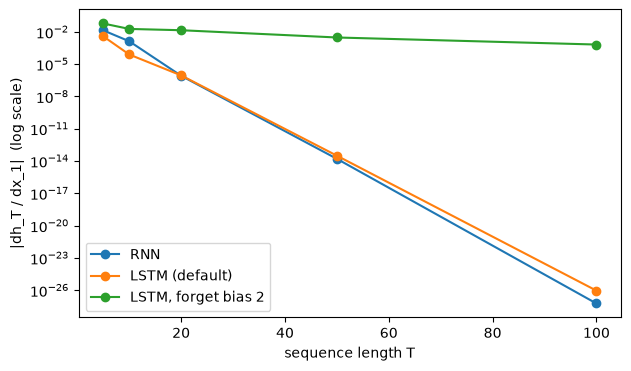

In [22]:
H = 16

def make_net(kind):
    if kind == "RNN":
        return nn.RNN(1, H, batch_first=True)
    net = nn.LSTM(1, H, batch_first=True)
    if kind == "LSTM, forget bias 2":
        with torch.no_grad():
            net.bias_ih_l0[H:2 * H] = 2.0   # order i, f, g, o: f is the second block of H entries
    return net

def first_input_gradient(net, T):
    x = torch.randn(32, T, 1, requires_grad=True)      # 32 random sequences of length T
    output, _ = net(x)
    output[:, -1].sum().backward()
    return x.grad[:, 0].abs().mean().item()            # average |gradient| w.r.t. the FIRST input

lengths = [5, 10, 20, 50, 100]
plt.figure(figsize=(7, 4))
for kind in ["RNN", "LSTM (default)", "LSTM, forget bias 2"]:
    grads = []
    for T in lengths:
        torch.manual_seed(0)
        grads.append(first_input_gradient(make_net(kind), T))
    print(f"{kind:20s}", "  ".join(f"T={T}: {g:.1e}" for T, g in zip(lengths, grads)))
    plt.semilogy(lengths, grads, "o-", label=kind)
plt.xlabel("sequence length T"); plt.ylabel("|dh_T / dx_1|  (log scale)"); plt.legend(); plt.show()

torch.manual_seed(0)
assert first_input_gradient(make_net("LSTM, forget bias 2"), 50) > 1e-4, "check both TODOs"
assert first_input_gradient(make_net("RNN"), 50) < 1e-8

**Questions 2.**
1. In 2a, which values of $w$ make the influence of $x_1$ **vanish**, and which make it **explode**? Why is either a problem when the network must learn something that depends on an input 50 steps ago?
2. In 2b, which case is "remembering"? Why does $f = 1, i = 0$ keep the cell state **exactly**, while a simple RNN always changes its hidden state?
3. Describe the three curves in 2d. Use 2a and 2b to explain why the LSTM with an open forget gate keeps a much larger gradient.
4. In one sentence each: what do the forget gate, the input gate, and the output gate decide?

**Your answer:**

1. $|w| < 1$ (0.5 and 0.9) makes the influence **vanish**: $0.5^{49} \approx 1.8 \times 10^{-15}$ and $0.9^{49} \approx 0.0057$. $|w| > 1$ (1.1) makes it **explode**: $1.1^{49} \approx 107$, and it keeps growing exponentially with $T$. The gradient $\partial h_T / \partial x_1$ follows the same factor, so for a dependency 50 steps back it is either ~0, and the weights get no learning signal from that input, or huge, and training becomes unstable (giant steps, NaNs). Only $w$ very close to 1 works, and that is hard to keep during training.

2. **keep** ($f=1, i=0$) is remembering: $c_t = 1 \cdot c_{t-1} + 0 \cdot g = c_{t-1}$ exactly. The cell-state update is **additive** and gated, with no squashing nonlinearity and no weight matrix applied to $c_{t-1}$, so the old value passes through unchanged. A simple RNN always computes $h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b)$: the old state is always multiplied by $W_{hh}$ and passed through tanh, so it cannot simply copy itself forward.

3. The **RNN** and the **default LSTM** fall in a straight line on the log scale, i.e. exponentially: from about $10^{-2}$ at $T=5$ to $10^{-14}$ at $T=50$ and $10^{-27}$ at $T=100$. The **LSTM with forget bias 2** stays almost flat: $6\times10^{-2}$ at $T=5$ and still $6.6\times10^{-4}$ at $T=100$. Along the cell-state path the gradient is multiplied by $f$ at each step ($\partial c_t / \partial c_{t-1} = f$), so it behaves like $f^{T-1}$ from 2a. In the default LSTM $f \approx \sigma(0) = 0.5$, which is the $w=0.5$ row and vanishes fast. With bias 2, $f \approx 0.88$, close to the "keep" case of 2b, so it behaves like the $w=0.9$ row and decays far more slowly. The RNN has no such additive path and is always squashed by tanh and $W_{hh}$.

4. - **Forget gate:** how much of the old cell state $c_{t-1}$ to keep.
   - **Input gate:** how much of the new candidate $g$ to write into the cell state.
   - **Output gate:** how much of the cell state, via $\tanh(c_t)$, to show as the hidden state $h_t$ (the output used by the next layer and the next step).

## Task 3 — A name generator (about 45 minutes)
We train a **character-level language model** on 32,000 English first names: at every step it reads one letter and predicts the **next** letter. Then it invents new names, one letter at a time. The vocabulary is 27 symbols: `.` (start/end of a name) and `a`–`z`.

**3a. Data.** All names are joined into one long text `.emma.olivia.ava. …` and cut into chunks of 20 characters. For each chunk, the target is the same text **shifted one character to the left**: the correct "next letter" at every position.

By hand first: for the text `.emma.olivia.` with chunks of length 5, the first chunk is `x = ".emma"` with targets `y = "emma."`. Write down `x` and `y` for the **second** chunk.

In [23]:
if not os.path.exists("names.txt"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/makemore/master/names.txt", "names.txt")
words = open("names.txt").read().split()
random.Random(0).shuffle(words)
print(len(words), "names, for example:", words[:8])

chars = "." + "abcdefghijklmnopqrstuvwxyz"
V = len(chars)                                   # 27
stoi = {ch: i for i, ch in enumerate(chars)}     # letter -> number
decode = lambda ids: "".join(chars[i] for i in ids)

def make_chunks(names, T):
    text = "." + ".".join(names) + "."
    ids = torch.tensor([stoi[ch] for ch in text])
    n = (len(ids) - 1) // T
    x = ids[:n * T].view(n, T)
    y = ids[1:n * T + 1].view(n, T)              # the same as x, but shifted one character to the left
    return x, y

# TODO: your hand answer for the second chunk
hand_x1, hand_y1 = ".oliv", "olivi"     # text .emma.olivia. -> chars 5..9 and 6..10
x_small, y_small = make_chunks(["emma", "olivia"], 5)
print("first chunk: ", decode(x_small[0]), "->", decode(y_small[0]))
assert decode(x_small[1]) == hand_x1 and decode(y_small[1]) == hand_y1

T = 20
split = int(0.9 * len(words))
x_train, y_train = make_chunks(words[:split], T)
x_val, y_val = make_chunks(words[split:], T)
print("train:", tuple(x_train.shape), " val:", tuple(x_val.shape))
assert torch.equal(x_train[:, 1:], y_train[:, :-1])

32033 names, for example: ['sanii', 'rhyson', 'lida', 'gennady', 'ottis', 'kervens', 'lolita', 'guillermina']
first chunk:  .emma -> emma.
train: (10272, 20)  val: (1135, 20)


**3b. The model.** Each letter enters as a **one-hot** vector of length 27 (all zeros except a 1 at the letter's position). The RNN or LSTM reads the letters, and a linear layer turns the hidden state at **every** step into 27 scores for the next letter. Complete `forward`.

`state` is the memory carried between calls: `None` at the start, then whatever `self.rnn` returned. For `nn.RNN` it is $h$; for `nn.LSTM` it is the pair $(h, c)$ — you do not have to handle the difference, just pass it along.

In [24]:
class CharModel(nn.Module):
    def __init__(self, cell, hidden_size=128):
        super().__init__()
        rnn_class = nn.RNN if cell == "rnn" else nn.LSTM
        self.rnn = rnn_class(input_size=V, hidden_size=hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, V)

    def forward(self, ids, state=None):
        # ids: (batch, seq_len) letter numbers
        x = F.one_hot(ids, V).float()          # (batch, seq_len, 27)
        output, state = self.rnn(x, state)     # output: (batch, seq_len, hidden)
        logits = self.fc(output)               # (batch, seq_len, 27)
        return logits, state

for cell, expected in [("rnn", rnn_params_by_hand), ("lstm", lstm_params_by_hand)]:
    m = CharModel(cell)
    logits, _ = m(x_train[:4])
    assert logits.shape == (4, T, V)
    assert sum(p.numel() for p in m.parameters()) == expected + 128 * V + V, "should be Task 1c + the Linear layer"
print("CharModel OK")

CharModel OK


**3c. Training.** `F.cross_entropy` expects a list of predictions of shape `(N, 27)` and a list of targets of shape `(N,)`, so we flatten the batch and time dimensions together: `(batch, seq_len, 27) -> (batch * seq_len, 27)`. Complete `sequence_loss` and the four training lines.

We use `torch.optim.Adam`, a variant of gradient descent that adapts the step size for each parameter; you may treat it as a black box.

RNN: loss before training 3.299
  epoch 1: validation loss 2.287
  epoch 2: validation loss 2.251
  epoch 3: validation loss 2.215
  epoch 4: validation loss 2.189
  epoch 5: validation loss 2.182
  3 seconds
LSTM: loss before training 3.293
  epoch 1: validation loss 2.291
  epoch 2: validation loss 2.188
  epoch 3: validation loss 2.144
  epoch 4: validation loss 2.116
  epoch 5: validation loss 2.098
  5 seconds


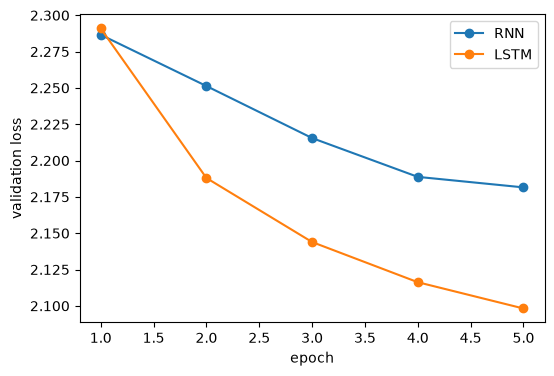

In [25]:
def sequence_loss(model, x, y):
    logits, _ = model(x)
    return F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))

def train(model, epochs=5, lr=0.005, batch_size=64):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(x_train))
        for start in range(0, len(x_train), batch_size):
            idx = perm[start:start + batch_size]
            loss = sequence_loss(model, x_train[idx], y_train[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            history.append(sequence_loss(model, x_val, y_val).item())
        print(f"  epoch {epoch + 1}: validation loss {history[-1]:.3f}")
    return history

models, histories = {}, {}
for cell in ["rnn", "lstm"]:
    torch.manual_seed(0)
    models[cell] = CharModel(cell)
    with torch.no_grad():
        start_loss = sequence_loss(models[cell], x_val, y_val).item()
    print(f"{cell.upper()}: loss before training {start_loss:.3f}")
    assert abs(start_loss - math.log(27)) < 0.1, "an untrained model should be close to ln(27)"
    t0 = time.time(); histories[cell] = train(models[cell]); print(f"  {time.time() - t0:.0f} seconds")

plt.figure(figsize=(6, 4))
for cell, hist in histories.items():
    plt.plot(range(1, len(hist) + 1), hist, "o-", label=cell.upper())
plt.xlabel("epoch"); plt.ylabel("validation loss"); plt.legend(); plt.show()
assert histories["lstm"][-1] < 2.25, "the LSTM should reach a validation loss below 2.25; check your training loop"

**3d. Generate new names.** Start from `.`, predict the next letter, **sample** one letter from the predicted probabilities, feed it back in, and repeat until the model produces `.` again. The hidden state is passed from one step to the next, so the model remembers the letters it has already written. Complete the two TODOs.

In [26]:
def generate(model, n_names, seed=0):
    gen = torch.Generator().manual_seed(seed)
    model.eval()
    names = []
    with torch.no_grad():
        for _ in range(n_names):
            ids, state, name = torch.tensor([[0]]), None, ""     # start with "." and an empty memory
            for _ in range(20):
                logits, state = model(ids, state)                 # one step; logits shape (1, 1, 27)
                probs = F.softmax(logits[0, -1], dim=0)           # 27 probabilities that sum to 1
                next_id = torch.multinomial(probs, 1, generator=gen).item()
                if next_id == 0:                                  # "." means the name is finished
                    break
                name += chars[next_id]
                ids = torch.tensor([[next_id]])
            names.append(name)
    return names

known = set(words)
for cell, model in models.items():
    samples = generate(model, 200, seed=1)
    print(f"{cell.upper()}: {', '.join(samples[:15])}")
    print(f"     {sum(s in known for s in samples) / 200:.0%} of 200 generated names appear in the training list\n")
assert len(generate(models["lstm"], 3)) == 3

RNN: ameleyg, laasal, hanshors, jaque, brilyn, jorselci, revy, madlaigh, caera, dacelian, alalie, shais, maias, tyam, braxin
     14% of 200 generated names appear in the training list

LSTM: anzor, gilma, aldin, xalissa, dezabem, rari, rielci, rean, madlaiyah, aera, dacelia, kalllyn, shord, maido, type
     16% of 200 generated names appear in the training list



**3e. Look inside.** Just run the cells. The first plot shows the LSTM's probabilities for the next letter after three different beginnings. The second shows how 24 of its 128 hidden units change while it reads a name.

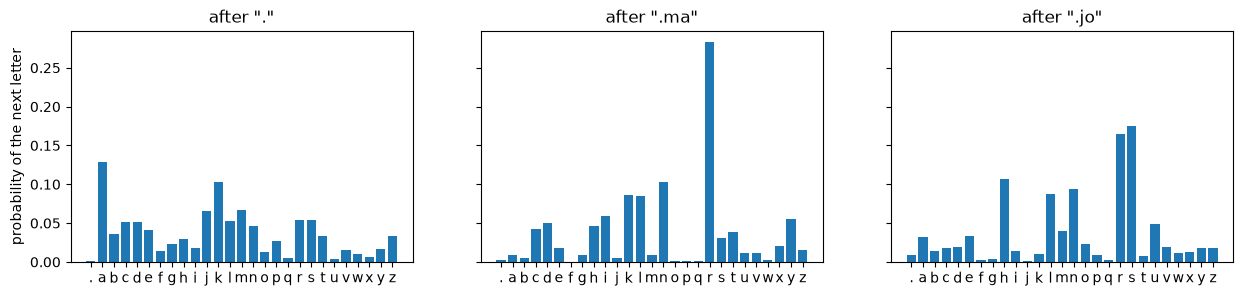

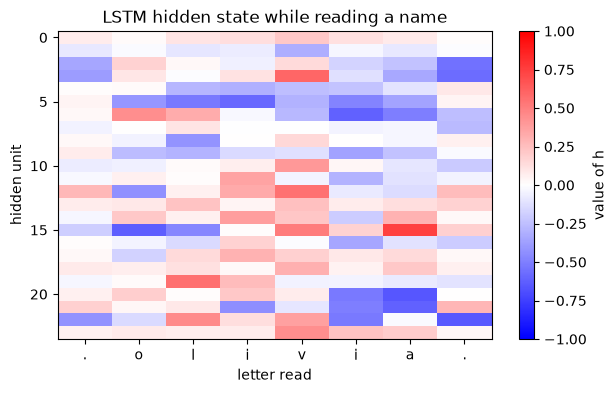

In [27]:
def next_letter_probs(model, prefix):
    with torch.no_grad():
        logits, _ = model(torch.tensor([[stoi[ch] for ch in prefix]]))
    return F.softmax(logits[0, -1], dim=0)

fig, axes = plt.subplots(1, 3, figsize=(15, 3), sharey=True)
for ax, prefix in zip(axes, [".", ".ma", ".jo"]):
    ax.bar(list(chars), next_letter_probs(models["lstm"], prefix))
    ax.set_title(f'after "{prefix}"')
axes[0].set_ylabel("probability of the next letter"); plt.show()

name = ".olivia."
with torch.no_grad():
    states, _ = models["lstm"].rnn(F.one_hot(torch.tensor([[stoi[ch] for ch in name]]), V).float())
plt.figure(figsize=(7, 4))
plt.imshow(states[0, :, :24].T, cmap="bwr", vmin=-1, vmax=1, aspect="auto")
plt.xticks(range(len(name)), list(name)); plt.xlabel("letter read"); plt.ylabel("hidden unit")
plt.colorbar(label="value of h"); plt.title("LSTM hidden state while reading a name"); plt.show()

**Questions 3.**
1. Before training, the loss was about 3.30. Show that this equals $\ln 27$ and explain why an untrained model gets exactly this value.
2. Compare the RNN and the LSTM: final validation loss and the generated names. Which is better, and is the difference large here? (Names are short — think about Task 2.)
3. In 3e, the probabilities after `.ma` and `.jo` are very different, but the model's input at that moment is a single letter (`a` or `o`). Where does the difference come from?
4. The model only ever predicts **one** next letter. How does `generate` turn that into a whole name? Why do we **sample** instead of always taking the most likely letter?

**Your answer:**

1. $\ln 27 = 3.2958 \approx 3.30$. The loss for one prediction is $-\ln p(\text{correct letter})$. An untrained model has small random weights, so its 27 logits are all close to each other and the softmax is nearly uniform, $p \approx 1/27$ for every letter. Then the loss is $-\ln(1/27) = \ln 27$ at every position, whatever the target. (We measured 3.299 and 3.293.)

2. After 5 epochs the LSTM is better: validation loss **2.098** against **2.182** for the RNN. Both produce plausible names (LSTM: *gilma, aldin, xalissa, dacelia, madlaiyah*; RNN: *jaque, brilyn, caera, dacelian*), and both reproduce about 14–16% of real names. The gap is real but small. Names are short (about 6 letters), so the next letter depends mostly on the last few letters, which a simple RNN can still remember. As Task 2 showed, the RNN's memory only becomes a real problem over dozens of steps, which is where the LSTM's gated cell state pays off.

3. From the **hidden state**. At that moment the input is just `a` or `o`, but the model also receives the state carried from the earlier letters `.m` or `.j`, so it "knows" the whole prefix. After `.ma` it strongly prefers `r` (*mar…*: Maria, Mark) and also `k`, `l`, `n`. After `.jo` it prefers `s`/`r` (*Jose, Jordan*), `h` (*John*), `l`/`n`. The prefix is stored in $h$ (and $c$), not in the current input.

4. It is **autoregressive**. It starts from `.`, predicts a distribution for the next letter, picks one, feeds that letter back in as the next input, and carries the hidden state forward. It repeats this until it produces `.` (end of name) or reaches 20 letters. We **sample** because always taking the most likely letter (greedy) is deterministic: from `.` it would always produce the same single name, and it often gets stuck in repetitive high-probability patterns. Sampling follows the learned distribution, so we get many different names, including rarer but plausible letter choices.

**Optional (temperature).** With $\tau = 0.5$ the logits are scaled up, so the softmax becomes sharper and the model mostly picks its top choices. The names are safe, common-looking and quite real (*anahi, aisha, kalina, delina, maida*). With $\tau = 1.5$ the distribution is flatter and unlikely letters are chosen more often. The names get more adventurous and often unpronounceable (*dhlexaorsun, brixfa, kalaliey*). $\tau = 1$ is the model's actual learned distribution; $\tau \to 0$ becomes greedy.

**Optional (not required).** *Temperature* controls how adventurous the generator is: divide the logits by a number $\tau$ before the softmax. Generate 15 names with $\tau = 0.5$ and $\tau = 1.5$ and describe the difference.

In [28]:
def generate_temp(model, n_names, tau, seed=0):
    gen = torch.Generator().manual_seed(seed)
    model.eval()
    names = []
    with torch.no_grad():
        for _ in range(n_names):
            ids, state, name = torch.tensor([[0]]), None, ""
            for _ in range(20):
                logits, state = model(ids, state)
                probs = F.softmax(logits[0, -1] / tau, dim=0)    # divide by the temperature before softmax
                next_id = torch.multinomial(probs, 1, generator=gen).item()
                if next_id == 0:
                    break
                name += chars[next_id]
                ids = torch.tensor([[next_id]])
            names.append(name)
    return names

for tau in [0.5, 1.5]:
    samples = generate_temp(models["lstm"], 15, tau, seed=1)
    print(f"tau = {tau}: {', '.join(samples)}")

tau = 0.5: anahi, garia, aldin, salissa, delina, kayline, kaciya, kalina, aisha, andric, charlon, lalie, shail, maida, tyliann
tau = 1.5: nozor, glemara, dhlexaorsun, dezabem, rari, rielci, rean, madlaiyah, aera, dacelia, kalaliey, chis, maiko, typi, brixfa


## Submission checklist
- [ ] Every `# TODO` filled, every `assert` passes, **Kernel → Restart & Run All** works
- [ ] All **Your answer** cells written (Questions 1, 2, 3)
- [ ] Hand calculations for 1a, 1c, 2a, 2b, and 3a done on paper first

**References**